# Mini Assignment: Logistic Regression vs Random Forest untuk Klasifikasi Kanker
**Nama:** WINARNO | **NIM:** B1C024030 | **Kelas:** A

Dataset: *Breast Cancer Wisconsin (Diagnostic)* dari scikit-learn. Label: `0 = malignant (ganas)`, `1 = benign (jinak)`.

In [21]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
import os
os.makedirs('results', exist_ok=True)

## 1. Load Dataset

In [22]:
data = load_breast_cancer()
X, y = data.data, data.target
print('Jumlah data  :', X.shape[0])
print('Jumlah fitur :', X.shape[1])
print('Distribusi kelas:')
print(pd.Series(y).map({0:'malignant (ganas)',1:'benign (jinak)'}).value_counts())

Jumlah data  : 569
Jumlah fitur : 30
Distribusi kelas:
benign (jinak)       357
malignant (ganas)    212
Name: count, dtype: int64


## 2. Pembagian Data: 70% Training, 30% Testing
Menggunakan `stratify=y` agar proporsi kelas sama di train dan test, dan `random_state=42` agar hasil reprodusibel. Split yang sama dipakai untuk kedua algoritma.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
print('Training:', X_train.shape[0], '| Testing:', X_test.shape[0])

Training: 398 | Testing: 171


## 3. Training Model
- **Logistic Regression** dengan standardisasi fitur (agar solver konvergen).
- **Random Forest** dengan 100 pohon (tidak memerlukan scaling).

In [24]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
rf = RandomForestClassifier(n_estimators=100, random_state=42)

log_reg.fit(X_train, y_train)
rf.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_pred_rf = rf.predict(X_test)

## 4. Evaluasi: Accuracy, Precision, Recall, F1-score
Kelas positif dalam metrik ini adalah **malignant (0)**, karena itu kelas yang paling penting dideteksi pada konteks kanker (`pos_label=0`).

In [25]:
def evaluate(name, y_true, y_pred):
    return {'Model': name,
            'Accuracy':  accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, pos_label=0),
            'Recall':    recall_score(y_true, y_pred, pos_label=0),
            'F1-score':  f1_score(y_true, y_pred, pos_label=0)}

results = pd.DataFrame([evaluate('Logistic Regression', y_test, y_pred_lr),
                        evaluate('Random Forest',       y_test, y_pred_rf)]).set_index('Model')
display(results.round(4))

for name, yp in [('Logistic Regression', y_pred_lr), ('Random Forest', y_pred_rf)]:
    print('=== ', name, ' ===')
    print(classification_report(y_test, yp, target_names=['malignant','benign'], digits=4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9883,0.9844,0.9844,0.9844
Random Forest,0.9357,0.9206,0.9062,0.9134


===  Logistic Regression  ===
              precision    recall  f1-score   support

   malignant     0.9844    0.9844    0.9844        64
      benign     0.9907    0.9907    0.9907       107

    accuracy                         0.9883       171
   macro avg     0.9875    0.9875    0.9875       171
weighted avg     0.9883    0.9883    0.9883       171

===  Random Forest  ===
              precision    recall  f1-score   support

   malignant     0.9206    0.9062    0.9134        64
      benign     0.9444    0.9533    0.9488       107

    accuracy                         0.9357       171
   macro avg     0.9325    0.9298    0.9311       171
weighted avg     0.9355    0.9357    0.9356       171



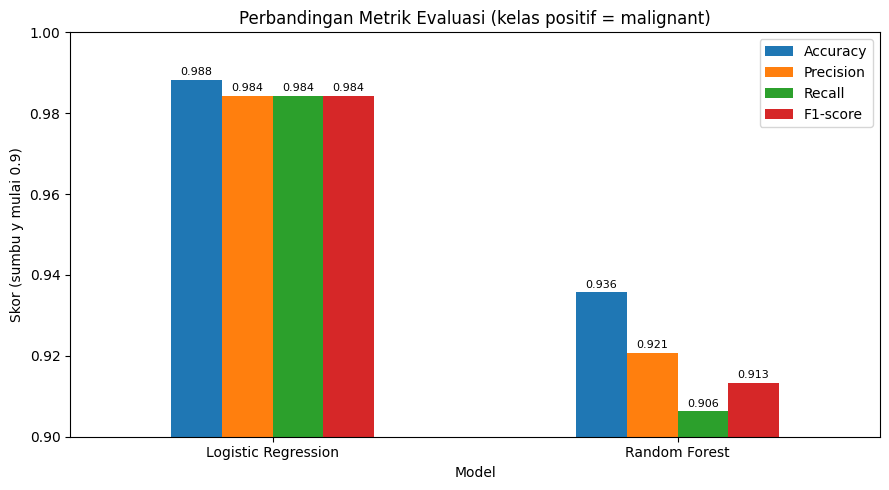

In [26]:
ax = results.plot(kind='bar', figsize=(9,5), ylim=(0.9,1.0), rot=0)
ax.set_title('Perbandingan Metrik Evaluasi (kelas positif = malignant)')
ax.set_ylabel('Skor (sumbu y mulai 0.9)')
for cont in ax.containers: ax.bar_label(cont, fmt='%.3f', fontsize=8, padding=2)
plt.tight_layout()
plt.savefig('results/evaluation_results.png', dpi=150)
plt.show()

## 5. Confusion Matrix

Logistic Regression 
 [[ 63   1]
 [  1 106]] 

Random Forest 
 [[ 58   6]
 [  5 102]] 



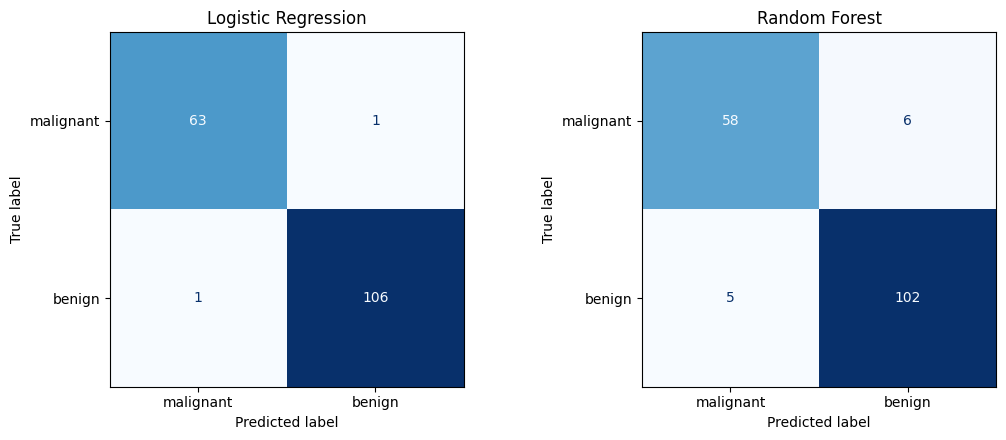

In [27]:
labels = ['malignant','benign']
fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
for ax, (name, yp) in zip(axes, [('Logistic Regression', y_pred_lr), ('Random Forest', y_pred_rf)]):
    cm = confusion_matrix(y_test, yp, labels=[0,1])
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    print(name, '\n', cm, '\n')
plt.tight_layout()
plt.savefig('results/confusion_matrix.png', dpi=150)
plt.show()

In [28]:
# Rincian kesalahan
for name, yp in [('Logistic Regression', y_pred_lr), ('Random Forest', y_pred_rf)]:
    tn_m, fp_m, fn_m, tp_m = confusion_matrix(y_test, yp, labels=[0,1]).ravel()
    print(f'{name}: ganas terdeteksi benar={tn_m}, GANAS DIPREDIKSI JINAK (False Negative)={fp_m}, '
          f'jinak diprediksi ganas (False Positive)={fn_m}, jinak benar={tp_m}')

Logistic Regression: ganas terdeteksi benar=63, GANAS DIPREDIKSI JINAK (False Negative)=1, jinak diprediksi ganas (False Positive)=1, jinak benar=106
Random Forest: ganas terdeteksi benar=58, GANAS DIPREDIKSI JINAK (False Negative)=6, jinak diprediksi ganas (False Positive)=5, jinak benar=102


## 6. Validasi Silang (cek stabilitas)
Satu split bisa kebetulan menguntungkan satu model, jadi dicek juga dengan 5-fold stratified CV pada seluruh data.

In [29]:
from sklearn.model_selection import cross_validate, StratifiedKFold
skf = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in [('Logistic Regression', log_reg), ('Random Forest', rf)]:
    cv = cross_validate(m, X, y, cv=skf, scoring={'acc':'accuracy','rec':'recall_macro'} )
    # recall malignant:
    from sklearn.metrics import make_scorer
    cv2 = cross_validate(m, X, y, cv=skf, scoring={'recall_malignant': make_scorer(recall_score, pos_label=0),
                                                    'accuracy':'accuracy'})
    rows.append({'Model':name,
                 'CV Accuracy (mean±sd)': f"{cv2['test_accuracy'].mean():.4f} ± {cv2['test_accuracy'].std():.4f}",
                 'CV Recall malignant (mean±sd)': f"{cv2['test_recall_malignant'].mean():.4f} ± {cv2['test_recall_malignant'].std():.4f}"})
display(pd.DataFrame(rows).set_index('Model'))

,CV Accuracy (mean±sd),CV Recall malignant (mean±sd)
Model,,
Logistic Regression,0.9737 ± 0.0166,0.9436 ± 0.0525
Random Forest,0.9561 ± 0.0123,0.9389 ± 0.0503


## 7. Analisis dan Kesimpulan

### Perbandingan kedua algoritma
Pada data uji (171 sampel), **Logistic Regression** unggul di semua metrik: accuracy 0.9883, precision 0.9844, recall 0.9844, F1 0.9844. **Random Forest** mendapat accuracy 0.9357, precision 0.9206, recall 0.9062, F1 0.9134.

Dari Confusion Matrix, Logistic Regression hanya membuat 2 kesalahan (1 False Negative, 1 False Positive), sedangkan Random Forest membuat 11 kesalahan (6 False Negative, 5 False Positive). Artinya Random Forest melewatkan 6 pasien kanker ganas yang diprediksi jinak.

### Catatan kehati-hatian
Hasil validasi silang 5-fold menunjukkan selisih yang lebih kecil (accuracy 0.9737 vs 0.9561; recall malignant 0.9436 vs 0.9389, dengan simpangan baku sekitar 0.05). Jadi keunggulan Logistic Regression pada satu split ini sebagian dipengaruhi pembagian data, dan data uji hanya 171 sampel. Dugaan penyebab Logistic Regression unggul adalah fitur dataset ini cukup mudah dipisahkan secara linear setelah distandardisasi, sehingga model sederhana sudah memadai. Ini dugaan dan belum diuji di eksperimen ini.

### Mengapa accuracy saja tidak cukup pada klasifikasi kanker
1. **Biaya kesalahan tidak sama.** False Negative (kanker ganas diprediksi jinak) dapat menunda pengobatan dan berakibat fatal, sedangkan False Positive umumnya hanya berujung pemeriksaan lanjutan. Accuracy menganggap keduanya setara.
2. **Data bisa tidak seimbang.** Pada kasus nyata, kanker jauh lebih jarang daripada kasus sehat. Model yang selalu menebak jinak bisa memiliki accuracy tinggi (pada dataset ini sekitar 62.6%) tanpa mendeteksi kanker sama sekali.
3. **Recall dan precision memberi informasi tambahan.** Recall menunjukkan berapa banyak kasus ganas yang berhasil terdeteksi, precision menunjukkan seberapa dapat dipercaya prediksi ganas, dan F1 menyeimbangkan keduanya. Pada skrining kanker, recall biasanya diprioritaskan.
4. **Confusion Matrix menunjukkan jenis kesalahan**, sesuatu yang disembunyikan oleh satu angka accuracy.

### Kesimpulan
Pada eksperimen ini Logistic Regression memberikan hasil klasifikasi lebih baik daripada Random Forest, terutama pada recall kelas malignant (0.9844 vs 0.9062) dan jumlah False Negative (1 vs 6). Namun, kesimpulan ini sebaiknya diperkuat dengan validasi silang dan tuning hyperparameter. Untuk deteksi kanker, evaluasi model harus menekankan recall dan jumlah False Negative, bukan accuracy semata.